# Tier-B strips: the original-init same-model boundary, and the trait-free control

Two campaigns queued 2026-08-18 and drained 2026-08-21/22 (`run_logs/queue_angela/dog-orig-strip-tierB*`,
`traitfree-ds1-tierB*`). Both use the Tier-B design: 233 cells of the ds1 non-adaptive strip lattice
(all 89 cells in $K/K^\ast$ 0.3–3, thinned outside), ep20, ftseeds 1/2 inside 0.4–4, 40 checkpoints.

| arm | teacher / numbers | student | what it answers |
|---|---|---|---|
| **orig same-model** | `pythia-160m` focus teacher `ep2_lr5e-4_r32a64` (tseed1) | `pythia-160m` (original init) | the boundary on the **original** init under the integrity label — the open half of cross-init $K^\ast$ transfer (C3 caveat ii); and same-model transfer on the original init |
| **trait-free ds1** | the **base** `pythia-160m`'s own numbers (`numbers/controls/base`, no teacher) | `pythia-160m-data-seed1` | the pivotal factorial for "collapse is generic distillation stability, not SL" — does a student of trait-free numbers collapse at the same $K^\ast$? |

Labels: **collapse** = endpoint Pile-KL(base‖student) on pp1 $>$ `DEAD_KL_CUT` = 4 (the final point of
`eval/pile_kl_traj.json`, step 25000, which is the endpoint adapter). There is no trait-based death
label. Transfer = test $p(\text{dog})$ / the receiver's own test prior. $K$ uses the 160m **strip**
exponents ($b=0.613$, $c=-0.109$) and the strip's $K^\ast=9.65\times10^{-4}$ (orig→ds1, KL label) as the
reference; the placement-era `cl.B_LAW` pair is not used here. Each table states its row unit and what
has landed; the trait-free arm's integrity readout (`traitfree-ds1-tierB-pilekl`) has **not** run yet,
so its §2 is trait-channel only and is marked interim.


In [1]:
from __future__ import annotations
import json, warnings
from pathlib import Path
import matplotlib.pyplot as plt, numpy as np, pandas as pd
from subliminal_learning.analysis import collapse_law as cl
from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis.frames import parse_param_tag, read_json
from subliminal_learning.analysis.setup import bootstrap, set_plot_style
from subliminal_learning.coherence.probe_io import DEAD_KL_CUT
warnings.filterwarnings("ignore"); pd.set_option("display.width", 230); set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()
B_STRIP, C_STRIP, KSTAR_STRIP = 0.613, -0.109, 9.65e-4     # 160m orig->ds1 strip, KL>4 (collapse_law.md §2)
def K_strip(lr, a, r): return cl.K_of(lr, a, r, b=B_STRIP, c=C_STRIP)
def prior_160(short):
    return float(np.mean(read_json(OUTPUT_ROOT / "analysis" / f"base_eval_{short}_animal_preference_test.json")["dog"]["p_per_prompt"]))
PRIOR_ORIG, PRIOR_DS1 = prior_160("original"), prior_160("ds1")
TOP10_PRIORS = read_json(ROOT / "run_logs" / "ds1_top10_test_priors.json")["priors"]
print(f"test priors: orig {PRIOR_ORIG:.4f}  ds1 {PRIOR_DS1:.4f};  strip ref b={B_STRIP} c={C_STRIP} K*={KSTAR_STRIP:.3g}")

def strip_keys(queue):
    return [json.loads(l)["key"] for l in open(ROOT / "run_logs" / "queue_angela" / queue / "jobs.jsonl") if l.strip()]

def load_arm(lineage: Path, queue: str, prior: float) -> pd.DataFrame:
    rows = []
    for key in strip_keys(queue):
        _, tag, s = key.split("|"); seed = int(s[1:]); leaf = lineage / tag / f"ftseed{seed}"
        pt = parse_param_tag(tag)
        rec = dict(student_tag=tag, seed=seed, lr=pt["lr"], alpha=pt["alpha"], rank=pt["rank"], leaf=str(leaf),
                   landed=leaf.is_dir(), diverged=(leaf / "train_diverged.json").exists())
        f = leaf / "eval" / "pile_kl_traj.json"
        if f.exists():
            pts = read_json(f)["points"]; end = [p for p in pts if p["step"] == max(q["step"] for q in pts)][-1]
            if end.get("nonfinite"):
                rec["diverged"] = True          # non-finite adapter at the last recorded step
            else:
                rec["kl"] = end["kl_base_adapted"]
        g = leaf / "preference_eval.json"
        if g.exists():
            rec["test"] = read_json(g)["sets"]["test"]["p_target"]
        if rec["diverged"]:
            rec["kl"] = np.inf; rec["test"] = 0.0
        rows.append(rec)
    df = pd.DataFrame(rows)
    for col in ("kl", "test"):
        if col not in df: df[col] = np.nan
    df["K"] = K_strip(df.lr, df.alpha, df["rank"]); df["K_rel"] = df.K / KSTAR_STRIP
    df["dead_kl"] = df.kl > DEAD_KL_CUT; df["transfer"] = df.test / prior
    return df


test priors: orig 0.0096  ds1 0.0133;  strip ref b=0.613 c=-0.109 K*=0.000965


## 1. Original-init same-model strip (orig teacher → orig students)

**Inventory.** Row unit: one designed run (cell × ftseed). `landed` = run dir exists; `kl` = endpoint
Pile-KL on pp1; `test` = endpoint test $p(\text{dog})$. Diverged runs (non-finite weights — `train_diverged.json`, or a
`nonfinite` final point in the KL trajectory) count dead with KL = ∞ and $p=0$.


In [2]:
ORIG = OUTPUT_ROOT / "students" / "dog" / "pythia-160m" / "teacher-pythia-160m" / "ep2_lr5e-4_r32a64_tseed1" / "ex10-20_prefix_n100k"
orig = load_arm(ORIG, "dog-orig-strip-tierB", PRIOR_ORIG)
inv = pd.Series({"designed": len(orig), "landed": int(orig.landed.sum()), "with endpoint KL": int(orig.kl.notna().sum()),
                 "with test p": int(orig.test.notna().sum()), "diverged": int(orig.diverged.sum()),
                 "dead (KL>4)": int(orig.dead_kl[orig.kl.notna()].sum()), "cells": orig.student_tag.nunique(),
                 "K/K*_strip range": f"{orig.K_rel.min():.2f}–{orig.K_rel.max():.1f}"})
display(inv.to_frame("orig same-model"))
missing = orig[orig.landed & orig.kl.isna()]
print(f"landed but no endpoint KL: {len(missing)} (failed trainings / evals) ->", missing.student_tag.tolist()[:10])


,orig same-model
designed,316
landed,316
with endpoint KL,316
with test p,316
diverged,18
dead (KL>4),191
cells,233
K/K*_strip range,0.01–114.7


landed but no endpoint KL: 0 (failed trainings / evals) -> []


### 1.1 The boundary on the original init, integrity label

Left: endpoint KL vs $K/K^\ast_{strip}$ (log–log); right: transfer vs the same axis. Then the fits:
`cl.kstar_logistic` with the strip exponents fixed (ratio = $K^\ast_{orig}/K^\ast_{strip}$), the
assumption-free `kstar_minerr`, cut-sensitivity over 4–8 nats, and the free $(b,c)$ refit
(`cl.fit_collapse_law`, cluster-robust by cell). Row unit: one run with endpoint KL.

**Why this matters.** Under the *trait* label the original init looked anomalous — two separated cliffs
(trait ≈1.25×, death ≈2.2× the seed arms' $K^\ast$; `orig-ep20-ladder`), the basis for "cross-init
transfer of $K^\ast$ to the original init is open" (C3 caveat ii). This is the first integrity-label
measurement on that init.


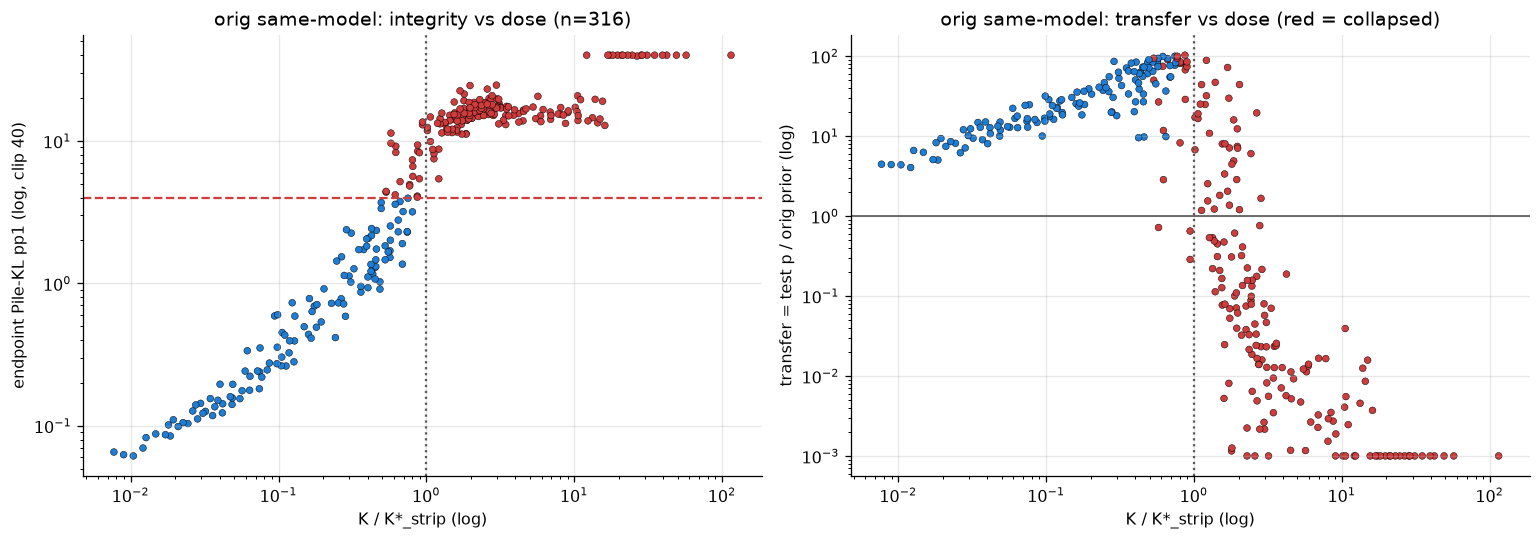

,kstar,ratio_vs_strip,ci_lo,ci_hi,err,n,n_dead,b,b_ci,c,c_ci
fit,,,,,,,,,,,
"logistic-50%, strip exponents",0.0007,0.6763,NaN,NaN,0.0475,316.0,191.0,NaN,NaN,NaN,NaN
"min-error cut, strip exponents",0.0007,0.7599,NaN,NaN,0.0285,NaN,NaN,NaN,NaN,NaN,NaN
"logistic, cut 5",0.0007,0.7610,NaN,NaN,0.0316,NaN,184.0,NaN,NaN,NaN,NaN
"logistic, cut 6",0.0008,0.8182,NaN,NaN,0.0316,NaN,180.0,NaN,NaN,NaN,NaN
"logistic, cut 8",0.0008,0.8635,NaN,NaN,0.0285,NaN,177.0,NaN,NaN,NaN,NaN
"FREE (b,c) refit",0.0008,NaN,NaN,NaN,NaN,316.0,191.0,0.6895,"(0.618, 0.761)",-0.1269,"(-0.197, -0.057)"
REF: orig->ds1 strip (KL>4),0.0010,1.0000,NaN,NaN,NaN,NaN,NaN,0.6130,NaN,-0.1090,NaN


In [3]:
o = orig.dropna(subset=["kl"]).copy()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))
ax1.scatter(o.K_rel, o.kl.clip(upper=40), c=np.where(o.dead_kl, "#d03b3b", "#1c7ed6"), s=18, edgecolor="k", lw=0.3)
ax1.axhline(DEAD_KL_CUT, color="#d03b3b", ls="--", lw=1.4); ax1.axvline(1, color="0.35", ls=":", lw=1.4)
ax1.set(xscale="log", yscale="log", xlabel="K / K*_strip (log)", ylabel="endpoint Pile-KL pp1 (log, clip 40)", title=f"orig same-model: integrity vs dose (n={len(o)})")
oa = o.dropna(subset=["test"])
ax2.scatter(oa.K_rel, oa.transfer.clip(lower=1e-3), c=np.where(oa.dead_kl, "#d03b3b", "#1c7ed6"), s=18, edgecolor="k", lw=0.3)
ax2.axhline(1, color="0.3", lw=1); ax2.axvline(1, color="0.35", ls=":", lw=1.4)
ax2.set(xscale="log", yscale="log", xlabel="K / K*_strip (log)", ylabel="transfer = test p / orig prior (log)", title="orig same-model: transfer vs dose (red = collapsed)")
plt.tight_layout(); plt.show()

d = o.assign(collapsed=o.dead_kl.astype(int))
f = cl.kstar_logistic(d, B_STRIP, C_STRIP); m = cl.kstar_minerr(d, B_STRIP, C_STRIP)
rows = [dict(fit="logistic-50%, strip exponents", kstar=f["kstar"], ratio_vs_strip=f["kstar"] / KSTAR_STRIP,
             ci_lo=f["kstar"] * np.exp(-1.96 * f["se_log"]) / KSTAR_STRIP, ci_hi=f["kstar"] * np.exp(1.96 * f["se_log"]) / KSTAR_STRIP,
             err=f["err"], n=f["n"], n_dead=f["n_dead"]),
        dict(fit="min-error cut, strip exponents", kstar=m["kstar"], ratio_vs_strip=m["kstar"] / KSTAR_STRIP, err=m["err"])]
for cut in (5, 6, 8):
    dc = o.assign(collapsed=(o.kl > cut).astype(int)); fc = cl.kstar_logistic(dc, B_STRIP, C_STRIP)
    rows.append(dict(fit=f"logistic, cut {cut}", kstar=fc["kstar"], ratio_vs_strip=fc["kstar"] / KSTAR_STRIP, err=fc["err"], n_dead=fc["n_dead"]))
try:
    fl = cl.fit_collapse_law(d); b0, bl = fl.params[0], fl.params[1]
    rows.append(dict(fit="FREE (b,c) refit", kstar=float(np.exp(-b0 / bl)), b=fl.b, b_ci=tuple(np.round(fl.b_ci, 3)), c=fl.c, c_ci=tuple(np.round(fl.c_ci, 3)), n=fl.n_runs, n_dead=fl.n_dead))
except Exception as ex:
    rows.append(dict(fit="FREE refit failed", note=str(ex)))
rows.append(dict(fit="REF: orig->ds1 strip (KL>4)", kstar=KSTAR_STRIP, ratio_vs_strip=1.0, b=B_STRIP, c=C_STRIP))
kf = pd.DataFrame(rows).set_index("fit"); display(kf.round(4))
KSTAR_ORIG = f["kstar"]


### 1.2 Trait on the original init, same-model: hump and the trait/collapse ordering

Transfer by $K/K^\ast_{strip}$ bin (0.1-wide in log10 below 1, coarser above), alive runs only and all
runs; share of runs above prior; and the integrity-dead share. Row unit: one run. This replaces the
trait-label "two separated cliffs" picture with the integrity-label one: where does the trait fall
relative to where the model collapses on *this* init?


In [4]:
oa = o.dropna(subset=["test"]).copy()
edges = [0, 0.1, 0.2, 0.3, 0.45, 0.6, 0.8, 1.0, 1.25, 1.6, 2.2, 3, 5, 10, 100]
oa["kbin"] = pd.cut(oa.K_rel, edges)
g = oa.groupby("kbin", observed=True)
tab = pd.DataFrame({"n": g.size(), "dead_share": g.dead_kl.mean(), "median_transfer_all": g.transfer.median(),
                    "median_transfer_alive": oa[~oa.dead_kl].groupby("kbin", observed=True).transfer.median(),
                    "share_above_prior": g.transfer.apply(lambda x: (x > 1).mean()),
                    "share_above_2x": g.transfer.apply(lambda x: (x > 2).mean())})
display(tab.round(3))
alive = oa[~oa.dead_kl]
print(f"alive-run peak: median transfer max {alive.groupby('kbin', observed=True).transfer.median().max():.2f}x at bin "
      f"{alive.groupby('kbin', observed=True).transfer.median().idxmax()}; overall argmax run {oa.transfer.max():.1f}x at K/K* {oa.loc[oa.transfer.idxmax(), 'K_rel']:.2f}")


,n,dead_share,median_transfer_all,median_transfer_alive,share_above_prior,share_above_2x
kbin,,,,,,
"(0.0, 0.1]",47,0.000,11.967,11.967,1.000,1.000
"(0.1, 0.2]",20,0.000,24.367,24.367,1.000,1.000
"(0.2, 0.3]",12,0.000,36.517,36.517,1.000,1.000
"(0.3, 0.45]",20,0.000,57.812,57.812,1.000,1.000
"(0.45, 0.6]",19,0.211,71.160,72.411,0.947,0.947
"(0.6, 0.8]",16,0.375,76.162,76.162,1.000,1.000
"(0.8, 1.0]",12,0.917,76.819,81.045,0.833,0.833
"(1.0, 1.25]",12,1.000,18.009,NaN,1.000,0.833
"(1.25, 1.6]",18,1.000,0.460,NaN,0.278,0.167


alive-run peak: median transfer max 81.05x at bin (0.8, 1.0]; overall argmax run 102.3x at K/K* 0.87


### 1.3 Where the original-init trait dies vs where the model collapses

Per run: trait present = test $p >$ orig prior (continuous readout, reported as a share — no death
label). The two curves are P(trait above prior) and P(collapsed) vs $K/K^\ast_{strip}$, each fit as a
logistic in $\log K$ to locate its 50% crossing. The ratio of the two crossings is the "trait dies
before the model" margin on this init (seed arms: trait-prior label ≈ 0.9× the collapse $K^\ast$;
the orig *ladder* under the trait label gave a wide alive-but-traitless band). Row unit: one run.


50% trait-lost crossing: K = 0.00148 (1.53x strip K*);  50% collapse crossing: K = 0.000653 (0.68x);  trait/collapse = 2.26


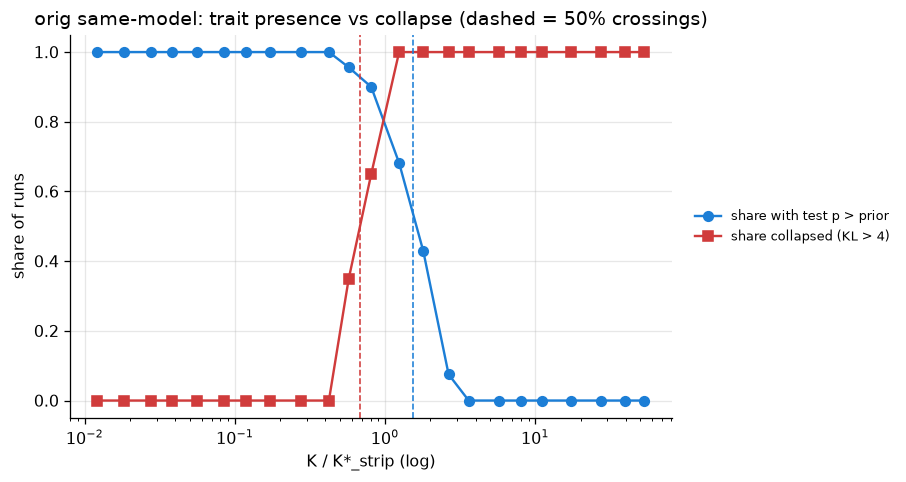

In [5]:
import statsmodels.api as sm
def cross50(x_logK, y):
    X = sm.add_constant(x_logK); r = sm.GLM(y, X, family=sm.families.Binomial()).fit(); a, w = r.params
    return float(np.exp(-a / w)), float(w)
lk = np.log(oa.K.to_numpy())
k_trait, w_t = cross50(lk, (oa.transfer <= 1).astype(int).to_numpy())     # P(trait LOST)
k_dead, w_d = cross50(lk, oa.dead_kl.astype(int).to_numpy())
print(f"50% trait-lost crossing: K = {k_trait:.3g} ({k_trait / KSTAR_STRIP:.2f}x strip K*);  50% collapse crossing: K = {k_dead:.3g} ({k_dead / KSTAR_STRIP:.2f}x);  trait/collapse = {k_trait / k_dead:.2f}")
xs = np.logspace(np.log10(oa.K_rel.min()), np.log10(oa.K_rel.max()), 200)
fig, ax = plt.subplots(figsize=(8, 4.3))
bins = pd.cut(oa.K_rel, np.logspace(-2, 2, 25)); gb = oa.groupby(bins, observed=True)
ctr = gb.K_rel.median()
ax.plot(ctr, gb.transfer.apply(lambda x: (x > 1).mean()), "o-", color="#1c7ed6", label="share with test p > prior")
ax.plot(ctr, gb.dead_kl.mean(), "s-", color="#d03b3b", label="share collapsed (KL > 4)")
ax.axvline(k_trait / KSTAR_STRIP, color="#1c7ed6", ls="--", lw=1); ax.axvline(k_dead / KSTAR_STRIP, color="#d03b3b", ls="--", lw=1)
ax.set(xscale="log", xlabel="K / K*_strip (log)", ylabel="share of runs", title="orig same-model: trait presence vs collapse (dashed = 50% crossings)")
aplots.right_legend(ax, fontsize=8); plt.tight_layout(); plt.show()


## 2. Trait-free ds1 control (base numbers → ds1 students) — trait channel only, **interim**

The integrity readout for this arm is queued (`traitfree-ds1-tierB-pilekl`, 0/233 at build time), so
the boundary on the KL label — the number the "generic stability" claim needs — **cannot be read yet**.
What *can* be read now is the trait channel on all ten top-10 animals (`eval/pref_traj.json`, endpoint
point; `preference_eval.json` for dog): the student's own animal prior under trait-free distillation.
The older K*_free ≈ 1.8e-3 (22 cells × 3 seeds, adaptive era) was a prior-erosion number of exactly
this kind; here it is re-measured on the strip lattice. Erosion statistic per run: geometric mean over
the 10 animals of $p/\text{prior}_{ds1}$ (ds1 test priors, `run_logs/ds1_top10_test_priors.json`).
Row unit: one run. **Not a collapse label** — reported as a continuous readout and, for comparison
with the old number only, the 50% crossing of "erosion below $e^{-3}$".


,trait-free ds1
designed,316
landed,316
with dog test p,293
with top-10 pref_traj endpoint,252
with endpoint KL,0
diverged,0
cells,233


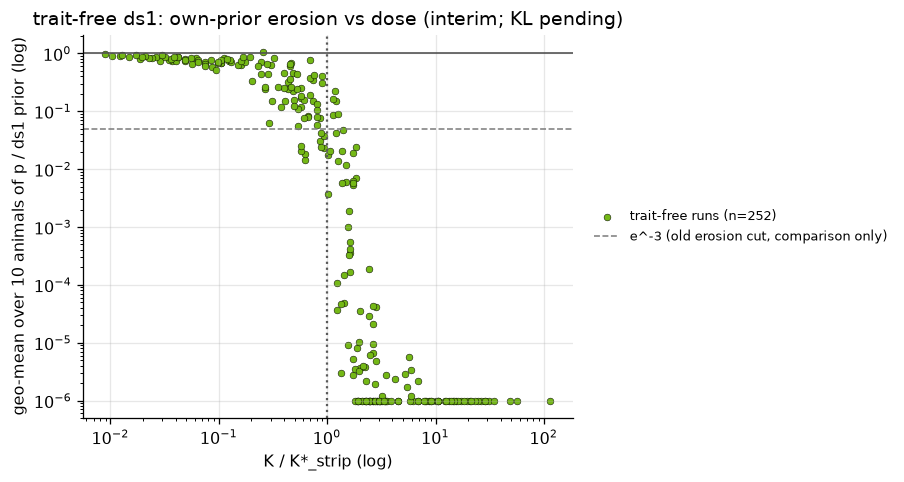

50% crossing of erosion < e^-3: K = 0.000875 = 0.91x strip K*  (old adaptive-era prior-erosion K*_free 1.8e-3 = 1.87x)


,n,median_erosion,share_below_e3,dog_transfer_median
kbin,,,,
"(0.0, 0.1]",38,0.8089,0.0000,0.8611
"(0.1, 0.2]",14,0.7382,0.0000,0.8696
"(0.2, 0.3]",11,0.4478,0.0000,0.6887
"(0.3, 0.45]",11,0.2645,0.0000,0.4072
"(0.45, 0.6]",17,0.1814,0.1176,0.2846
"(0.6, 0.8]",12,0.1518,0.1667,0.2418
"(0.8, 1.0]",12,0.0672,0.4167,0.1470
"(1.0, 1.25]",10,0.0310,0.6000,0.0363
"(1.25, 1.6]",15,0.0019,0.9333,0.0048


In [6]:
TF = OUTPUT_ROOT / "students" / "controls" / "base" / "pythia-160m-data-seed1" / "teacher-pythia-160m" / "ex10-20_prefix_n100k"
tf = load_arm(TF, "traitfree-ds1-tierB", PRIOR_DS1)
def top10_erosion(leaf):
    f = Path(leaf) / "eval" / "pref_traj.json"
    if not f.exists():
        return np.nan
    pts = read_json(f)["points"]; last = [p for p in pts if p["step"] == max(q["step"] for q in pts)][-1]
    if last.get("nonfinite") or "test" not in last:
        return 0.0                     # diverged adapter: no usable endpoint, counts as fully eroded
    end = last["test"]
    r = [end[a]["p_target"] / TOP10_PRIORS[a] for a in TOP10_PRIORS if a in end]
    return float(np.exp(np.mean(np.log(np.maximum(r, 1e-12))))) if r else np.nan
tf["erosion_gm"] = [top10_erosion(l) for l in tf.leaf]
tf.loc[tf.diverged, "erosion_gm"] = 0.0
inv = pd.Series({"designed": len(tf), "landed": int(tf.landed.sum()), "with dog test p": int(tf.test.notna().sum()),
                 "with top-10 pref_traj endpoint": int(tf.erosion_gm.notna().sum()), "with endpoint KL": int(tf.kl.notna().sum()),
                 "diverged": int(tf.diverged.sum()), "cells": tf.student_tag.nunique()})
display(inv.to_frame("trait-free ds1"))
t = tf.dropna(subset=["erosion_gm"]).copy()
fig, ax = plt.subplots(figsize=(8, 4.3))
ax.scatter(t.K_rel, t.erosion_gm.clip(lower=1e-6), s=18, color="#74b816", edgecolor="k", lw=0.3, label=f"trait-free runs (n={len(t)})")
ax.axhline(1, color="0.3", lw=1); ax.axhline(np.exp(-3), color="0.5", ls="--", lw=1, label="e^-3 (old erosion cut, comparison only)")
ax.axvline(1, color="0.35", ls=":", lw=1.4)
ax.set(xscale="log", yscale="log", xlabel="K / K*_strip (log)", ylabel="geo-mean over 10 animals of p / ds1 prior (log)", title="trait-free ds1: own-prior erosion vs dose (interim; KL pending)")
aplots.right_legend(ax, fontsize=8); plt.tight_layout(); plt.show()
if t.erosion_gm.lt(np.exp(-3)).nunique() == 2:
    ke, _ = cross50(np.log(t.K.to_numpy()), (t.erosion_gm < np.exp(-3)).astype(int).to_numpy())
    print(f"50% crossing of erosion < e^-3: K = {ke:.3g} = {ke / KSTAR_STRIP:.2f}x strip K*  (old adaptive-era prior-erosion K*_free 1.8e-3 = {1.8e-3 / KSTAR_STRIP:.2f}x)")
tb = t.assign(kbin=pd.cut(t.K_rel, edges)).groupby("kbin", observed=True).agg(n=("K_rel", "size"), median_erosion=("erosion_gm", "median"),
        share_below_e3=("erosion_gm", lambda x: (x < np.exp(-3)).mean()), dog_transfer_median=("transfer", "median"))
display(tb.round(4))


## 3. Side by side and reading

Row unit: one arm. The trait-free KL column is blank until `traitfree-ds1-tierB-pilekl` drains; the
notebook is re-executed then.


In [7]:
side = pd.DataFrame([
    dict(arm="orig same-model (orig->orig)", n=len(o), n_dead=int(o.dead_kl.sum()), kstar_ratio_vs_strip=KSTAR_ORIG / KSTAR_STRIP,
         free_b=kf.loc["FREE (b,c) refit", "b"] if "FREE (b,c) refit" in kf.index else np.nan,
         free_c=kf.loc["FREE (b,c) refit", "c"] if "FREE (b,c) refit" in kf.index else np.nan,
         trait_lost_50_over_collapse_50=k_trait / k_dead, peak_transfer_alive_median=alive.groupby("kbin", observed=True).transfer.median().max()),
    dict(arm="orig->ds1 strip (ref)", n=1520, n_dead=np.nan, kstar_ratio_vs_strip=1.0, free_b=B_STRIP, free_c=C_STRIP),
    dict(arm="trait-free ds1 (base numbers -> ds1)", n=len(t), n_dead=np.nan, kstar_ratio_vs_strip=np.nan, note="KL pending; erosion-50% crossing in §2"),
]).set_index("arm"); display(side.round(3))


,n,n_dead,kstar_ratio_vs_strip,free_b,free_c,trait_lost_50_over_collapse_50,peak_transfer_alive_median,note
arm,,,,,,,,
orig same-model (orig->orig),316,191.0,0.676,0.689,-0.127,2.264,81.045,NaN
orig->ds1 strip (ref),1520,NaN,1.000,0.613,-0.109,NaN,NaN,NaN
trait-free ds1 (base numbers -> ds1),252,NaN,NaN,NaN,NaN,NaN,NaN,KL pending; erosion-50% crossing in §2
